# `ratio_study` - 05 Vertical equity

The VEI, the Vertical Equity Panel, the VEM and the Gini family.

| Notebook | Covers |
|---|---|
| [01 Basics](01_basics.ipynb) | Sections 1-2: indicators, confidence intervals, compliance checks, IQR trimming, charts, comparisons |
| [02 Spatial](02_spatial.ipynb) | Section 3: ratio maps, Moran's I, hot/cold spots, the VEM map |
| [03 Reporting](03_reporting.ipynb) | Section 4: PDF / XLSX / CSV / PNG output |
| [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) | Sections 5 and 7: ML / SHAP inequity diagnostics and sales-chasing detection |
| [05 Vertical equity](05_vertical_equity.ipynb) | Section 6: VEI, the Vertical Equity Panel, VEM, the Gini family |

All five use the anonymised sample dataset bundled with the package - no data preparation required.
Section numbers are kept from the original single-notebook tour so cross-references still line up.

## Setup

Core install only; the interactive VEM chart in 6.4 needs `ratio_study[interactive]` (Plotly).

```
pip install "ratio_study[interactive]"
```

In [1]:
# Uncomment on first run.
# %pip install "ratio_study[interactive]"

In [2]:
import ratio_study as rs
import pandas as pd
import numpy as np
from pathlib import Path

# inline plotting must be enabled AFTER importing ratio_study
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sample_df = rs.load_sample_dataset()

MARKET_VALUE = 'time_adjusted_sale_price'   # the market value proxy
ASSESSMENT   = 'assessment_value_new'       # the value under test (current CAMA model)

sample_df['asr'] = sample_df[ASSESSMENT] / sample_df[MARKET_VALUE]   # ratio column, needed by the spatial and VE functions

print('ratio_study version:', rs.__version__)
print(f'{len(sample_df):,} sales, {sample_df.shape[1]} columns')

# Compliance ranges from the Standard (Table 11.1 residential improved; retiring PRD).
assessment_standards = {'Median': (0.90, 1.10),
                        'CoD':    (0.05, 0.15),
                        'VEI':    (-10.0, 10.0),
                        'PRB':    (-0.05, 0.05),
                        'PRD':    (0.98, 1.03)}

ratio_study version: 0.4.5
12,583 sales, 20 columns


---
# 6. A deeper dive into vertical equity

Vertical equity is the hardest thing a ratio study measures and the thing that matters
most, because failing it means tax burden is being shifted systematically between price
brackets — almost always onto the cheaper properties.

## 6.0 The measurement problem, and the market value proxy

The Standard spells out a subtlety that governs every measure in this section.

Vertical equity measures relate the ratio to market value — but market value is unknown.
Use **sale price** as the proxy and you create a *spurious correlation*: the sale price is
already the denominator of the ratio, so a property that happens to sell high gets both a
raised price and a lowered ratio. That biases the whole analysis **towards regressivity**.
Substitute assessed value and you get the same problem pointed the other way, towards
progressivity.

The Standard's remedy, used by both the VEI and the PRB, is a proxy that gives **equal
weight to both**, so the two biases partially offset:

$$\text{proxy} = 0.5 \times SP + 0.5 \times \frac{AV}{\widetilde{ASR}}$$

The package builds this proxy for you. `mkt_value_proxy_header=` overrides it if you have
something better — the Standard suggests listing prices or a well-tested
independent model.

## 6.1 What the Standard now recommends

The following table compares the three measures with established compliance ranges:

| Measure | Compliance range | Built-in statistical test | Visualisation |
|---|---|---|---|
| **VEI** — Vertical Equity Indicator | −10% to +10% | ✔ | ✔ |
| **PRB** — Price-Related Bias | −0.05 to +0.05 | ✔ | ✔ |
| **PRD** — Price-Related Differential | 0.98 to 1.03 | ✘ | ✘ |

**The VEI is the preferred measure.** The PRD has neither a built-in test nor a
visualisation, is biased toward regressivity, and is distorted by value and ratio outliers
— the Standard flags this as the last edition in which it counts for compliance.

The Standard lists further tests, none with compliance ranges but all informative:
Modified Kakwani / Gini, instrumental-variable regression, Mann-Whitney, Kruskal-Wallis and
Spearman rank. It recommends **running several**, since each has different blind spots.

This package implements the three standard measures, the Gini family and
Kruskal-Wallis, plus a moving-median measure (VEM) of its own.

## 6.2 VEI — the Vertical Equity Indicator

The calculation, step by step:

1. Compute the ratio for each sale.
2. Compute the equal-weight market value proxy above.
3. Sort by the proxy and split into quantile groups — **halves** for 20–50 sales,
   **quartiles** for 51–500, **deciles** for 501 or more. Below 20 sales the VEI is not
   defined (at least 10 sales per group are required).
4. Take the median ratio of each group.
5. $\mathrm{VEI} = 100 \times \dfrac{\widetilde{QG_{last}} - \widetilde{QG_{first}}}{\widetilde{ASR}}$

**A negative VEI is regressive; a positive VEI is progressive** — the high-value group's
median sitting *below* the low-value group's is the definition of regressivity. Within
±10% is acceptable; outside it, the confidence interval decides.

> **A caution on the published draft.** Some worked examples state that a **negative** VEI
> indicates regressivity, while a summary table and the glossary entry state the opposite.
> The arithmetic settles it, and that is the convention this package follows. Worth raising
> with the committee.

In [3]:
vei = rs.vei_analysis(sample_df['asr'],
                      sample_df[MARKET_VALUE],
                      conf_level=0.90,
                      acceptable_range=10,
                      percentile_method='R7')

print(f"VEI          : {vei['vei']:.2f}%")
print(f"direction    : {vei['direction']}")
print(f"conclusion   : {vei['conclusion']}")
print(f"quantile grps: {len(vei['pg_stats'])}  (n={len(sample_df):,} -> deciles)")

VEI: 10 quantile groups, R7 ranking (Appendix E.5); comparing groups 1 and 10.
VEI          : -9.43%
direction    : Regressivity
conclusion   : Acceptable
quantile grps: 10  (n=12,583 -> deciles)


### The quantile group table

The Standard says the group medians and their CODs should both be reviewed — and if an
*inner* group holds the highest or lowest median, that should be noted and investigated
even though the VEI itself only reads the first and last.

In [4]:
pg = pd.DataFrame(vei['pg_stats']).drop(columns=['asr_vector'])
pg.index = [f'Decile {i+1}' for i in range(len(pg))]
pg['cod'] = pg['cod'] * 100
pg.style.format({'med_proxy': '{:,.0f}', 'median_ratio': '{:.4f}',
                 'lower_ci': '{:.4f}', 'upper_ci': '{:.4f}',
                 'achieved_coverage': '{:.3f}', 'cod': '{:.2f}'}) \
        .set_caption('VEI quantile groups - median ratio and COD per decile')

,sales,med_proxy,median_ratio,lower_ci,upper_ci,achieved_coverage,cod
Decile 1,1259,"284,618",1.0491,1.0406,1.0581,0.900,11.15
Decile 2,1258,"325,862",1.0252,1.0176,1.0297,0.900,8.52
Decile 3,1258,"352,582",1.0218,1.0158,1.0262,0.900,7.41
Decile 4,1258,"378,103",1.0082,1.0026,1.0123,0.900,7.31
Decile 5,1259,"408,537",0.9907,0.9842,0.9947,0.900,8.91
Decile 6,1258,"447,586",0.9774,0.9723,0.9839,0.900,9.27
Decile 7,1258,"496,761",0.9868,0.9793,0.9939,0.900,9.61
Decile 8,1258,"562,992",0.9824,0.9761,0.9895,0.900,9.48
Decile 9,1258,"660,776",0.9772,0.9707,0.9833,0.900,9.75
Decile 10,1259,"861,798",0.9549,0.9462,0.9620,0.900,11.24


### Ranking method: R6 vs R7

The Standard notes that when the sample does not divide evenly among the quantile groups,
the nine standard quantile definitions can assign boundary observations differently and
produce slightly different VEIs. Its worked example differs by ~3 points between
methods (48.53% under R7, 51.43% under R6).

`percentile_method` selects between them. R7 is the default — it is also the default in R,
Excel, SAS and NumPy; SPSS and NCSS default to R6.

In [5]:
for method in ('R7', 'R6'):
    v = rs.vei_analysis(sample_df['asr'], sample_df[MARKET_VALUE],
                        conf_level=0.90, percentile_method=method)
    print(f'{method}: VEI = {v["vei"]:+.2f}%   ->  {v["direction"]}, {v["conclusion"]}')

VEI: 10 quantile groups, R7 ranking (Appendix E.5); comparing groups 1 and 10.
R7: VEI = -9.43%   ->  Regressivity, Acceptable
VEI: 10 quantile groups, R6 ranking (Appendix E.5); comparing groups 1 and 10.
R6: VEI = -9.42%   ->  Regressivity, Acceptable


### `compare_all_buckets` — where is the *worst* gap?

By construction the VEI reads only the first and last quantile groups. The Standard asks
the analyst to check the ones in between by eye: *"If another quantile group has the highest
or lowest median ratio, it should be noted and reviewed to identify any correctable
issues."*

`compare_all_buckets=True` does that check arithmetically. It finds the two groups with the
widest gap in median ratio and runs the whole analysis on those instead, printing which
groups they were. Value order is preserved, so the sign still reads the same way — negative
is regressive.

> **This is a diagnostic, not the compliance test.** The Standard defines the VEI on the
> lowest- and highest-value groups. A number produced this way is the worst gap in the
> range, not the VEI, and should not be quoted as compliance. Use it to find the stretch
> worth investigating, then report the standard VEI.

On this dataset the ratio falls fairly steadily with value, so the extremes *are* the
endpoints and the option changes nothing — which is itself the reassuring answer.

In [6]:
widest = rs.vei_analysis(sample_df['asr'],
                         sample_df[MARKET_VALUE],
                         conf_level=0.90,
                         compare_all_buckets=True)

print(f"\nVEI {widest['vei']:+.2f}%  ({widest['conclusion']})")

VEI: compare_all_buckets is ON - comparing the widest gap between any two of the 10 quantile groups, not just the first and last.
     Lowest median ratio : group 10 of 10 (0.9549)
     Highest median ratio: group 1 of 10 (1.0491)
     Comparing groups 1 and 10 in value order. This is a diagnostic, not the IAAO standard acceptance test.

VEI -9.43%  (Acceptable)


Where an *inner* band is the problem, the two differ. Here is a synthetic model whose
mid-priced properties are over-assessed while both ends are on level — the shape a single
first-versus-last comparison is blind to.

In [7]:
rng = np.random.default_rng(0)
demo_price = np.linspace(100_000, 900_000, 800)
demo_asr = np.where((demo_price > 350_000) & (demo_price < 550_000), 1.25, 1.00)
demo_asr = demo_asr + rng.normal(0, 0.02, demo_price.size)

print('--- Standard default: first vs last ---')
standard = rs.vei_analysis(demo_asr, demo_price, conf_level=0.90)
print(f"VEI {standard['vei']:+.2f}%  ->  {standard['conclusion']}\n")

print('--- compare_all_buckets: widest gap anywhere ---')
diagnostic = rs.vei_analysis(demo_asr, demo_price, conf_level=0.90,
                             compare_all_buckets=True)
print(f"VEI {diagnostic['vei']:+.2f}%  ->  {diagnostic['conclusion']}")

--- Standard default: first vs last ---
VEI: 10 quantile groups, R7 ranking (Appendix E.5); comparing groups 1 and 10.
VEI -0.66%  ->  Acceptable

--- compare_all_buckets: widest gap anywhere ---
VEI: compare_all_buckets is ON - comparing the widest gap between any two of the 10 quantile groups, not just the first and last.
     Lowest median ratio : group 10 of 10 (0.9954)
     Highest median ratio: group 5 of 10 (1.2493)
     Comparing groups 5 and 10 in value order. This is a diagnostic, not the IAAO standard acceptance test.
VEI -25.20%  ->  Regressivity


The default reports next to nothing — the bottom and top bands really are assessed alike.
The diagnostic finds the mid-range bulge the VEI was never designed to see. Both numbers
are correct answers to different questions, and the VEM chart in section 6.4 shows the same
thing continuously.

`ratios()` and `ratios_report()` take this as `vei_compare_all_buckets=`, and report it once
per study in the settings summary.

### Which ranking method drew the groups

The Standard makes the quantile definition part of the result, so every VEI chart now
carries it bottom-right — `10 quantile groups, R7 ranking` — and `ratios()` prints it once
per study alongside the confidence-interval settings. When `compare_all_buckets` is on, the
note names the pair that was compared as well.

### The VEI boxplot

The Standard's visualisation: one box per quantile group, so the median of
the lowest group can be read against the highest. A visible drift from left to right is
vertical inequity; flat boxes are the model behaving.

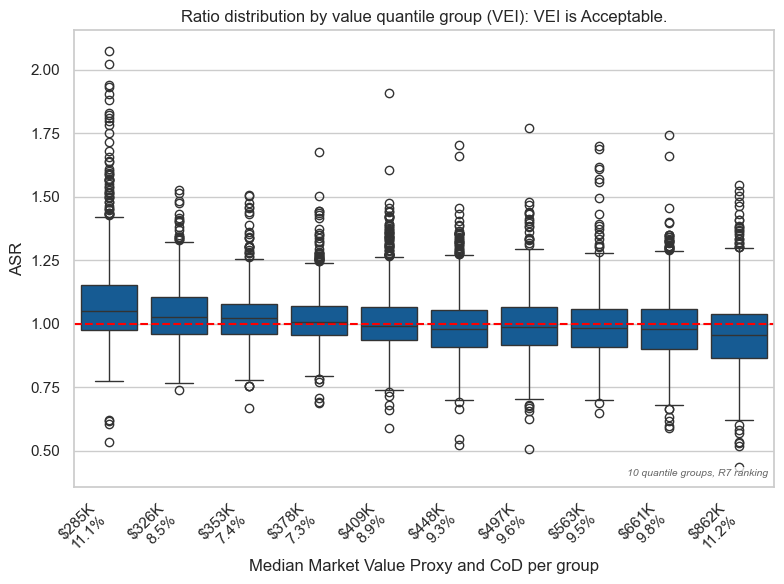

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [8]:
rs.vei_boxplot(sample_df['asr'],
               sample_df[MARKET_VALUE],
               vei,
               title='Ratio distribution by value quantile group (VEI)')

### Kruskal–Wallis across all groups

The Standard suggests supplementing the first-versus-last comparison with a Kruskal-Wallis
test across *all* quantile groups — the test for "three or more property groups are
appraised at equal percentages of market value".

In [9]:
kw = vei['kruskal_wallis']
print(f"Kruskal-Wallis H = {kw['statistic']:.1f}, p = {kw['pvalue']:.3g}")
print('-> the quantile groups do not all share one ratio distribution'
      if kw['pvalue'] < 0.05 else '-> no significant difference between quantile groups')

Kruskal-Wallis H = 718.9, p = 5.86e-149
-> the quantile groups do not all share one ratio distribution


## 6.3 The Vertical Equity Panel

The panel is the single view that answers *"is this model vertically equitable?"*. Four
compliance gauges — **PRB, PRD, VEI, VEM** — sit over the two charts that show *why*: the
VEM moving median across the value range, and the VEI boxplot by quantile group.

Each gauge is coloured against its standard, so the verdict is legible without knowing the
thresholds.

**The secondary-indicator strip.** Beneath the gauges sits a band of supporting tests, which
the Standard recommends running alongside the headline measures
*"as they may provide additional insights into potential valuation bias"*:

| | |
|---|---|
| **MKI** | Quintos' Modified Kakwani Index. Equity at 1.00; below 1 regressive |
| **RRI** | Reranking Index — how much assessment reorders properties relative to price (horizontal, not vertical) |
| **Mann-Whitney** | The Standard's two-group test, applied to the bottom and top halves of the value range |
| **Kruskal-Wallis** | The Standard's test across *all* quantile groups, not just the extremes |
| **Spearman** | Rank correlation of ratio against the value proxy; negative is regressive |

The three hypothesis tests are coloured by significance. **MKI and RRI are left neutral on
purpose** — the Standard gives them no compliance range, so colouring them pass/fail
would invent a standard that does not exist. They are numbers to read, not verdicts.

Note how easily the tests reach significance on 12,583 sales: a statistically detectable
tilt is not the same as a materially inequitable one, which is exactly why the gauges above
carry the compliance ranges and the strip does not.

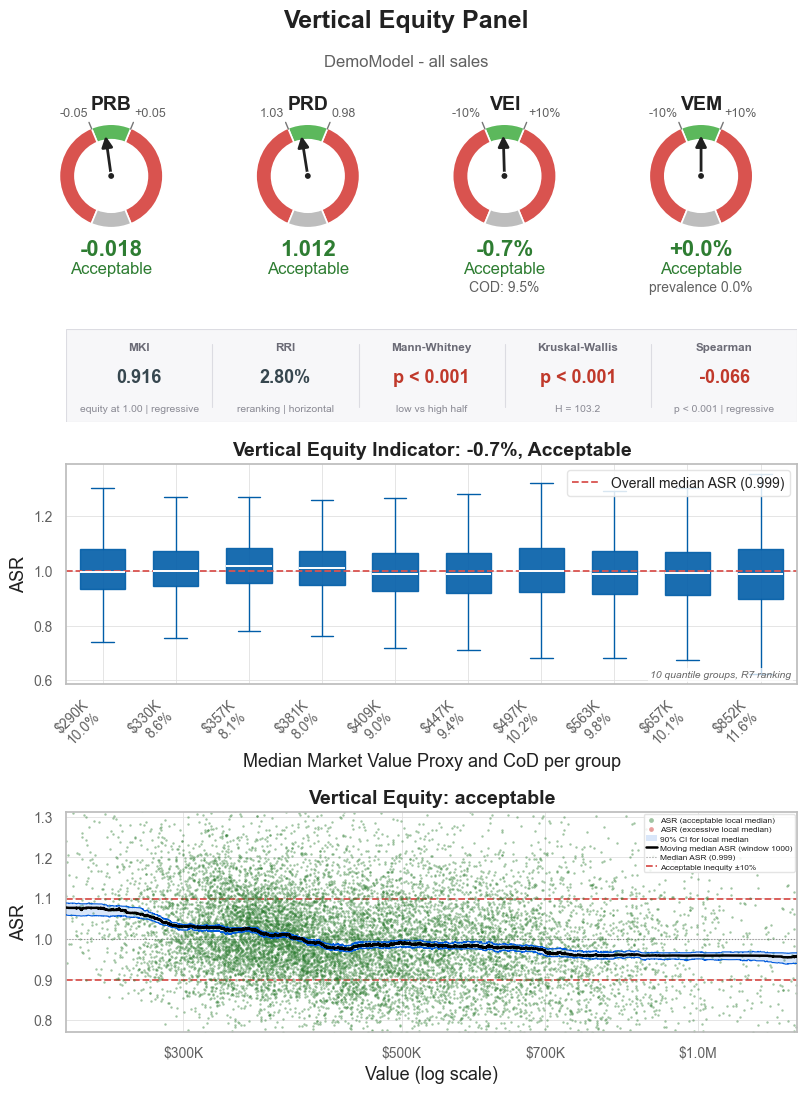

In [10]:
rs.vertical_equity_panel(sample_df,
                         assessment_header=ASSESSMENT,
                         market_value_header=MARKET_VALUE,
                         title='Vertical Equity Panel',
                         subtitle='DemoModel - all sales',
                         vei_conf_level=0.90,
                         vem_conf_level=0.90,
                         vem_acceptable_inequity_level=0.10,
                         x_scale='log')

Here's a version without the VEM, but keeping the scatterplot:

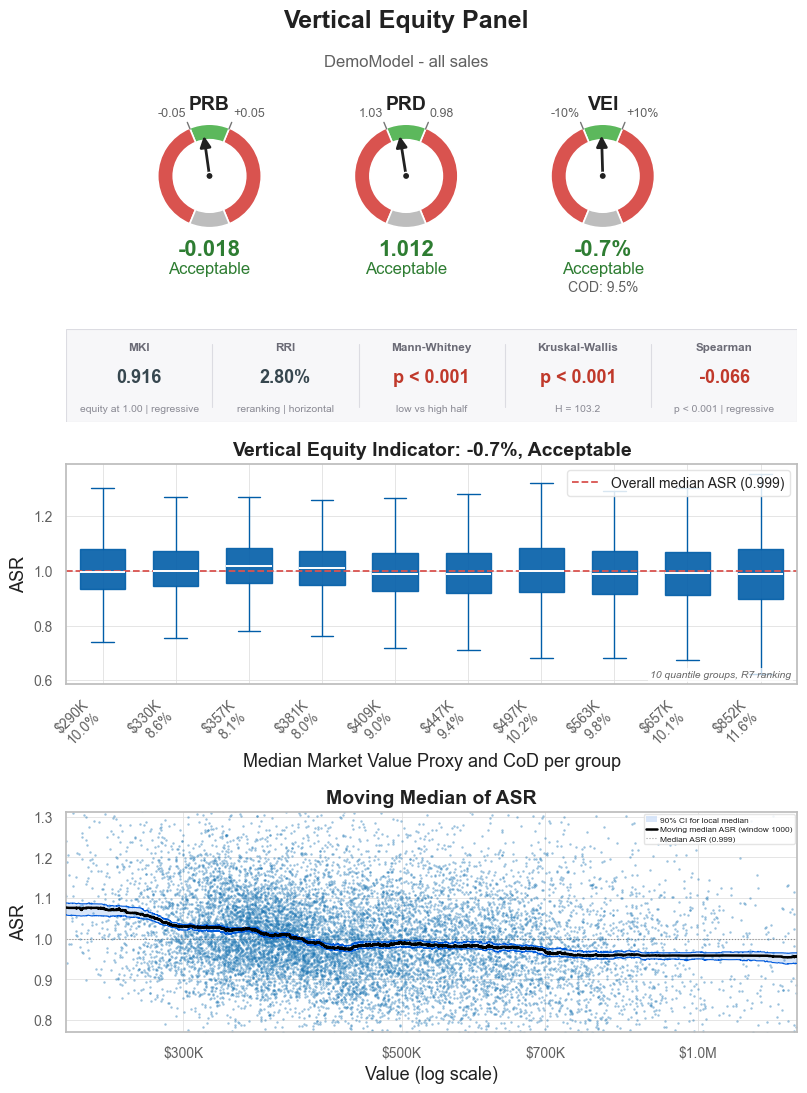

In [11]:
rs.vertical_equity_panel(sample_df,
                         assessment_header=ASSESSMENT,
                         market_value_header=MARKET_VALUE,
                         title='Vertical Equity Panel',
                         subtitle='DemoModel - all sales',
                         vei_conf_level=0.90,
                         vem_conf_level=0.90,
                         vem_acceptable_inequity_level=0.10,
                         x_scale='log', include_vem=False)

The Standard asks for vertical equity testing at the level of large geographic areas and major
property categories, and warns that testing over a stratum with a **narrow value range** is
less meaningful. The panel drops straight into a per-stratum loop — which is what
`pdf_vertical_equity_panel_groups=True` did to the report in section 4.2.

2,149 sales in this stratum


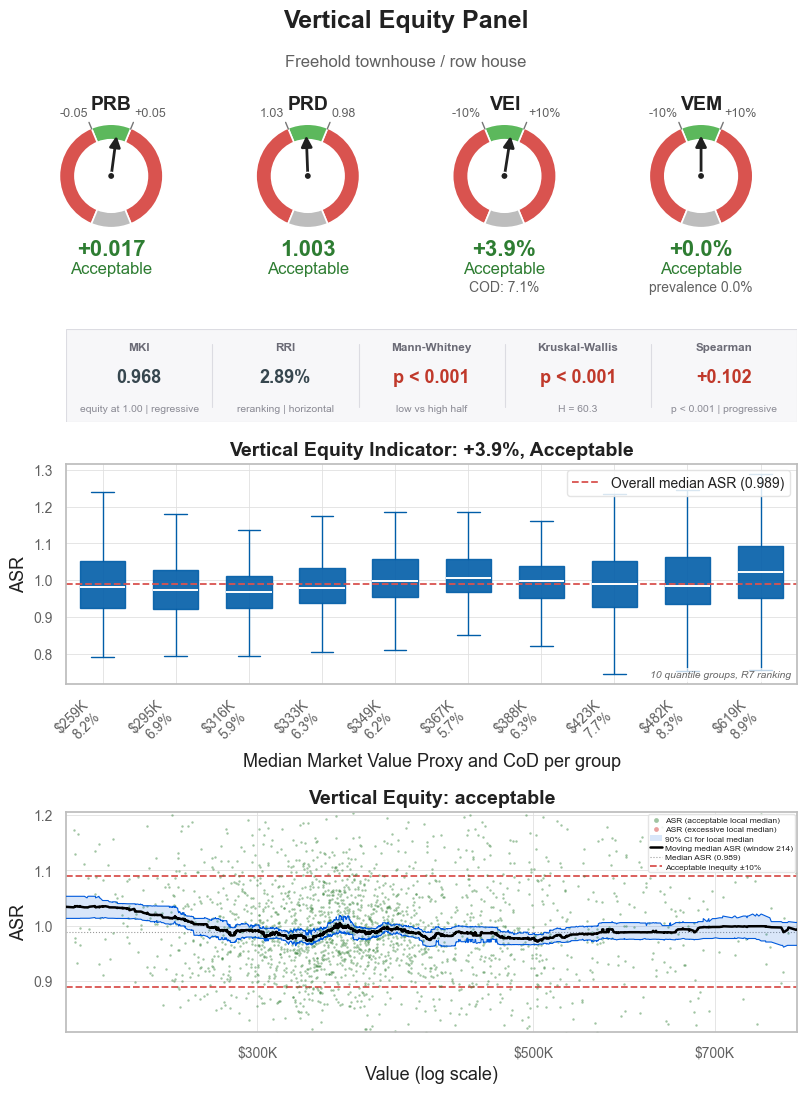

In [12]:
townhouses = sample_df[sample_df['property_type'].str.contains('townhouse', case=False, na=False)]
print(f'{len(townhouses):,} sales in this stratum')

rs.vertical_equity_panel(townhouses,
                         assessment_header=ASSESSMENT,
                         market_value_header=MARKET_VALUE,
                         title='Vertical Equity Panel',
                         subtitle='Freehold townhouse / row house')

## 6.4 VEM — the moving-median measure

**Not an IAAO measure** — this one is the package's own, and it exists to cover a gap the
Standard itself names. The Standard's own criticism of the PRB is that it *"may not permit a
complete understanding of the nature of any vertical inequity present, only its general
direction"*, and the VEI, by design, *"focuses attention on the lowest and highest quantile
groups"*. Neither tells you what happens in between.

The VEM tracks the **local median ratio** along the whole value range with a confidence
band, and treats any stretch whose band clears the acceptable level as inequity. That turns
one number into three:

- **`Inequity_severity`** — how far the confirmed excursions go, in percentage points
- **`Inequity_prevalence`** — how much of the value range is affected
- **`Inequity_conclusion`** — the direction, named only when the band confirms it

The band is built from order statistics of the local sample (an exact sign-test interval by
default, the same family used elsewhere in the Standard), so it can never fall outside the ratios
actually observed — which matters because the ASR is bounded below and unbounded above.

In [13]:
vem = rs.vem(sample_df,
             market_value_proxy=MARKET_VALUE,
             asr_col='asr',
             quantiles=20,
             conf_level=0.90,
             ci_method='binom',
             acceptable_inequity_level=0.10,
             generate_plot=True,
             plot_return_object=True,
             plot_title='Vertical Equity Moving Median')

pd.Series({k: v for k, v in vem.items()
           if not isinstance(v, (pd.DataFrame,)) and k != 'plot'}).to_frame('value')

,value
Inequity_severity,0.0
Inequity_prevalence,0.0
asr_center,0.998506
window_size,None
quantiles,20
Inequity_conclusion,acceptable


In [14]:
# Interactive Plotly chart - hover a point for the local median, its band and the group size.
vem['plot']

`vem_plot()` is the one-liner form, straight from the sales frame with no `asr` column
required:

In [15]:
rs.vem_plot(sample_df,
            assessment_header=ASSESSMENT,
            market_value_header=MARKET_VALUE,
            quantiles=20,
            conf_level=0.90,
            title='Vertical Equity Moving Median')

In [16]:
# The underlying window-by-window table, if you want to drive your own chart.
vem['dataframe'].head(20)

,mv,asr_raw,asr,quantile_group,moving_median,median_ci_lower,median_ci_upper,out_of_bounds,ci_out_of_bounds
2470,99812,1.311581,0.313075,0,0.073684,0.057264,0.08733,0,0
4949,102113,0.926352,-0.072154,0,0.073684,0.057264,0.08733,0,0
4948,104854,0.877512,-0.120994,0,0.073684,0.057264,0.08733,0,0
9588,110566,1.526500,0.527994,0,0.073684,0.057264,0.08733,0,0
3495,136126,1.140829,0.142323,0,0.073684,0.057264,0.08733,0,0
3496,140556,1.143055,0.144549,0,0.073684,0.057264,0.08733,0,0
4950,142302,0.958944,-0.039561,0,0.073684,0.057264,0.08733,0,0
6748,143748,1.932922,0.934416,0,0.073684,0.057264,0.08733,0,0
6747,147656,1.939754,0.941248,0,0.073684,0.057264,0.08733,0,0
8692,150876,1.808562,0.810056,0,0.073684,0.057264,0.08733,0,0


## 6.5 The Gini family

A different framing entirely. Rather than asking how the ratio moves with price, the Gini
approach compares the **inequality of the assessment distribution** to the **inequality of
the price distribution**. The Standard lists it as an additional test, citing Quintos (2020,
2021).

| Statistic | Meaning |
|---|---|
| `Gini_Sale_Prices` | Inequality of market value across the sample |
| `Gini_Assessments` | Inequality of assessed value |
| `Concentration_Index` | Inequality of assessments *ranked by sale price* |
| `Kakwani_Index` | `Concentration_Index − Gini_Sale_Prices`. Negative ⇒ regressive |
| `Modified_Kakwani_Index` | `Concentration_Index / Gini_Sale_Prices`. **Below 1 ⇒ regressive**, equity at 1 |
| `Reranking_Effect` / `Reranking_Index` | How much assessment *reorders* properties relative to price — pure horizontal inequity |
| `Redistributive_Effect` | Net effect of assessment on the distribution |

The Standard's caution: the MKI *"uses sale price as the market value proxy so can be prone to
regressive bias if measurement error in sale prices is sizable enough to significantly
reorder the sale price ranks"* — unlike the VEI and PRB, it does not use the equal-weight
proxy. Read it alongside them, not instead of them.

`MKI` and `RRI` are the columns that appeared in the section 2.4 indicator table.

In [17]:
gini = rs.gini_stats(sample_df[MARKET_VALUE],
                     sample_df[ASSESSMENT],
                     run_regression=True)

pd.Series({k: v for k, v in gini.items() if not isinstance(v, dict)}).to_frame('value').round(6)

,value
Gini_Sale_Prices,0.206532
Gini_Assessments,0.200513
Concentration_Index,0.189285
Redistributive_Effect,-0.006019
Kakwani_Index,-0.017247
Modified_Kakwani_Index,0.916493
Reranking_Effect,0.011228
Reranking_Index,0.027999


`run_regression=True` also fits the significance tests behind each index, so a departure
from equity can be reported as confirmed or not.

In [18]:
pd.DataFrame(gini['Regressions']).T

,slope,rsquared_adj,rsquared,f_pvalue,resid,fitted_values,intercept
Gini_Sale_Prices,"{'beta': 0.2065317045125151, 'pvalue': 0.0, 't...",0.664976,0.665003,0.0,"[-0.02917616191862739, -0.02840339373985311, -...","[0.06340902013287751, 0.06342543368326395, 0.0...","{'coefficient': 0.06339260658249107, 'pvalue':..."
Gini_Assessments,"{'beta': 0.2005129921306171, 'pvalue': 0.0, 't...",0.718103,0.718125,0.0,"[-0.03847612046491433, -0.034779734966827354, ...","[0.06641813716335644, 0.06643407239280336, 0.0...","{'coefficient': 0.06640220193390951, 'pvalue':..."
Concentration_Index,"{'beta': 0.1892847962085974, 'pvalue': 0.0, 't...",0.639922,0.639951,0.0,"[-0.026994421829439418, -0.039504229018497365,...","[0.07203178895906634, 0.07204683185791468, 0.0...","{'coefficient': 0.072016746060218, 'pvalue': 0..."
Kakwani_Index,"{'beta': -0.01724690830391773, 'pvalue': 1.896...",0.034913,0.03499,0.0,"[0.0021817400891880542, -0.011100835278644175,...","[0.008622768826188745, 0.008621398174650645, 0...","{'coefficient': 0.008624139477726845, 'pvalue'..."
Modified_Kakwani_Regression_Diagnostic,"{'beta': 0.6982607586358641, 'pvalue': 0.0, 't...",0.639922,0.639951,0.0,"[-0.10997207618895904, -0.05752597300182022, -...","[0.49042619938933374, 0.43807857750513557, 0.4...","{'coefficient': 0.3017392413641356, 'pvalue': ..."
Modified_Kakwani_Index,0.916493,0.916493,0.916493,0.916493,0.916493,0.916493,0.916493


### The Lorenz / concentration curve

The visual form of the same result — and the reason the Standard credits the Gini approach
with *"naturally has graphical qualities"*. The gap between the sale-price Lorenz curve and
the assessment concentration curve **is** the vertical inequity, and which curve sits above
the other gives the direction.

`lorenz_plot()` takes the sales frame directly.

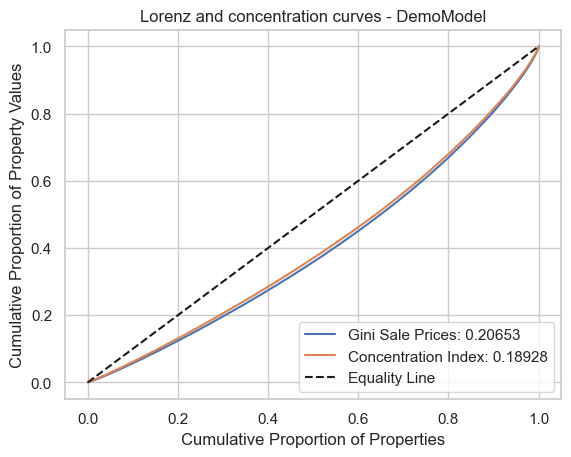

In [19]:
rs.lorenz_plot(sample_df,
               assessment_header=ASSESSMENT,
               market_value_header=MARKET_VALUE,
               title='Lorenz and concentration curves - DemoModel')

### Decomposing the Gini across strata

Quintos (2021) splits total inequality into a **within-group** component, a
**between-group** component, and a residual interaction term. That answers the question the
grouped ratio table cannot: *is the inequity coming from unfair treatment inside strata, or
from strata being pitched at different levels relative to each other?*

Run it through `ratios()` with `gini_args`.

In [20]:
decomp = rs.ratios(sample_df,
                   assessment_header=ASSESSMENT,
                   market_value_header=MARKET_VALUE,
                   group_by='property_type',
                   gini_args={'gini_decomposition': True},
                   return_dict=True)

decomp['dict_gini_decomposition']['property_type']['dataframe'].head(20)

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Effect,Group,Sales Count,Gini Sale Prices,Gini Assessments,Concentration Index,Modified Kakwani Index,Kakwani Index,Redistributive Effect,Reranking Effect,Reranking Index
0,Total,Sales Population,"12,583",0.206532,0.200513,0.189285,0.916493,-0.017247,-0.006019,0.011228,2.7999%
1,NaN,NaN,,,,,,,,,
2,Within,by: property_type,,,,,,,,,
3,,group_total,,,,,,-0.008686,,,
4,,Bed and breakfast,3,0.000000,0.000000,-0.000000,,-0.000000,0.000000,0.000000,0.0000%
5,,Duplex,354,0.000153,0.000142,0.000129,,-0.000025,-0.000013,0.000012,0.0035%
6,,Fiveplex,30,0.000002,0.000002,0.000002,,-0.000000,-0.000000,0.000000,0.0000%
7,,Fourplex,70,0.000009,0.000009,0.000008,,-0.000001,-0.000001,0.000001,0.0002%
8,,Freehold townhouse/row house,"2,149",0.003424,0.003506,0.003303,,-0.000109,0.000095,0.000204,0.0669%
9,,Group home,1,,,,,0.000000,,,0.0000%


### Which characteristics drive the inequality?

`gini_factors` decomposes the Gini coefficient of assessed value across the model's own
independent variables, attributing a share of total inequality to each. It answers *"which
variables in my model are generating the spread?"* — the distributional counterpart to the
SHAP importance ranking in section 5.2.

In [21]:
factors = rs.ratios(sample_df,
                    assessment_header=ASSESSMENT,
                    market_value_header=MARKET_VALUE,
                    gini_args={'gini_factors_variables': ['living_area', 'lotsize', 'frontage',
                                                          'quality_class', 'baths', 'bedrooms']},
                    return_dict=True)

factors['dict_gini_decomposition']['gini_factors']

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Variable,Mean,Elasticities,CI,Coefficient,Contribution,Factor MKI,% of Total MKI
0,living_area,1604.485258,0.771631,0.144155,232.984818,0.111235,0.554750,0.960587
1,quality_class,5.341254,0.150849,0.051400,13682.058484,0.007754,0.038669,0.066958
2,frontage,45.590843,0.083823,0.070875,890.712889,0.005941,0.029629,0.051304
3,baths,1.994199,0.009279,0.112939,2254.267094,0.001048,0.005227,0.009050
4,lotsize,0.102190,-0.000127,0.058760,-602.994173,-0.000007,-0.000037,-0.000065
5,bedrooms,3.315664,-0.154178,0.065970,-22527.068753,-0.010171,-0.050726,-0.087835


## 6.6 Putting it together

The Standard recommends running **multiple** vertical equity tests, because each has
different blind spots. Here they are side by side — and note that they need not agree:
disagreement is information about *which kind* of inequity is present.

In [22]:
ve_summary = rs.ratios(sample_df,
                       assessment_header=ASSESSMENT,
                       market_value_header=MARKET_VALUE,
                       indicators=['Median', 'CoD', 'VEI', 'PRB', 'PRD', 'VEM', 'MKI', 'RRI'],
                       descriptive=True,
                       assessment_standards=assessment_standards,
                       ci_seed=7)

ve_summary.T

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, CoD, PRB, PRD   <-- set
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,0
Level,Overall
Count,"12,583"
Median,0.9985
Median_ci,"(0.9968, 1.0001)"
CoD,9.48%
CoD_ci,"(9.36%, 9.61%)"
PRB,-0.0178
PRB_ci,"(-0.0216, -0.0139)"
PRD,1.0120
PRD_ci,"(1.0107, 1.0134)"


In [23]:
row = ve_summary.iloc[0]

verdict = pd.DataFrame([
    ('VEI (preferred)',        row['VEI'],       '-10% to +10%; negative = regressive'),
    ('VEI verdict',            '',               row['VEI_conclusion']),
    ('PRB',                    row['PRB'],       '-0.05 to +0.05; negative = regressive'),
    ('PRD (retiring)',         row['PRD'],       '0.98 to 1.03; above 1 = regressive'),
    ('VEM severity',           row['Inequity_severity'],   'percentage points outside the band'),
    ('VEM prevalence',         row['Inequity_prevalence'], 'share of the value range affected'),
    ('VEM verdict',            '',               row['Inequity_conclusion']),
    ('Modified Kakwani (MKI)', row['MKI'],       'below 1 = regressive'),
    ('Reranking index (RRI)',  row['RRI'],       'pure horizontal reordering'),
    ('COD (context)',          row['CoD'],       'read vertical equity only once this passes'),
], columns=['Measure', 'Value', 'Reading'])

verdict.style.hide(axis='index').set_caption(
    'Vertical equity, several ways - Standard on Ratio Studies, September 2026')

Measure,Value,Reading
VEI (preferred),-0.75,-10% to +10%; negative = regressive
VEI verdict,,Acceptable
PRB,-0.0178,-0.05 to +0.05; negative = regressive
PRD (retiring),1.0120,0.98 to 1.03; above 1 = regressive
VEM severity,0.00,percentage points outside the band
VEM prevalence,0.00,share of the value range affected
VEM verdict,,acceptable
Modified Kakwani (MKI),0.9165,below 1 = regressive
Reranking index (RRI),2.80%,pure horizontal reordering
COD (context),9.48%,read vertical equity only once this passes


The ML view of the same question - *how much of the ratio can property characteristics predict?* - is in [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) (section 5).

---
**Back to:** [01 Basics](01_basics.ipynb)